# 01 · One short call, one stock hedge, one cash ledger

**Objective:** follow a short European call from sale through expiry, accounting for the premium, stock trades, interest, transaction costs and final settlement. Then inspect the same hedge policy over 5,000 simulated outcomes.

The baseline selects **JPM**, rebalances every **five trading sessions**, and charges **5 basis points** on the absolute dollar value of each stock trade, including entry and liquidation. The input cell controls these choices.

This notebook is complete and runs independently from a fresh kernel. Its model inputs load from the same validated configuration as notebook 00; hedge-policy controls remain explicit below. No earlier notebook needs to be executed in the current kernel.

Prices follow illustrative correlated GBM under Q, with zero dividends and constant financing. Quantities are share-equivalent option units; there is no exchange contract multiplier. Results describe this simulation, rather than a historical trading record.

**Shared study inputs:** contract and scenario assumptions now load from `config/illustrative_study.json` through `load_named_inputs`. `Book` remains the validated model container. Change that file once to update the baseline across notebooks 00–03; policy/experiment controls stay explicit in each notebook. 


| Step | Purpose | Main functions/tools |
|---|---|---|
| 1–2 | Load packages and inspect named inputs | `Path`, dictionaries, `Book` |
| 3 | Reproduce the joint study paths and select one stock | `simulate_paths`, array slicing |
| 4 | Inspect opening exposures and run the hedge policy | `initial_exposures`, `hedge` |
| 5 | Understand opening cash and subsequent events | `result.ledger`, `.loc`, `.iloc` |
| 6–7 | Reconcile cash, marked value and final settlement | NumPy assertions and cash-flow tables |
| 8 | Isolate the effect of stock transaction costs | Matched zero-cost and costly runs |
| 9 | Summarize all simulated outcomes | `summarize`, histograms |
| 10 | Record inputs, policy choices and source versions | `provenance` |

The hedge logic lives in `hedging_harness/core.py`. Pricing and Greeks reuse the consolidated Black–Scholes module. The markdown below explains each calculation and the resulting account entries.

## 1 · Connect to the project

Locate the project root and put it on Python's import search path. This works with the kernel started in either `MonteCarloEvaluations` or `Hedging_Study_Notebooks`.

In [1]:
from pathlib import Path
from dataclasses import asdict, replace
from hashlib import sha256
import sys
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "hedging_harness" / "core.py").is_file():
    ROOT = ROOT.parent
assert (ROOT / "hedging_harness" / "core.py").is_file(), f"Wrong project root: {ROOT}"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from hedging_harness import Book, simulate_paths, hedge, summarize, initial_exposures, provenance

plt.rcParams.update({
    "figure.figsize": (10, 4), "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.2,
})
print(f"Project root: {ROOT}")

Project root: /Users/saireddivari/MonteCarloEvaluations


## 2 · Select a named option and hedge policy

The dictionaries below are loaded from the shared validated study file, preserving the explicit association between each name and its inputs. `notional / spot` gives the positive magnitude of the short-call quantity.

- `OPTION_NAME` selects the position to trade.
- `HEDGE_EVERY = 5` means rebalance every five sessions; `None` means hedge initially and then hold the stock until expiry.
- `COST_BPS = 5.0` means a one-way stock trading cost of `5 / 10000 = 0.0005`, or $5 per $10,000 traded.
- `AUDIT_PATH` selects the single simulated outcome whose full daily ledger is retained. All paths still contribute to the terminal distribution.

The hedge uses the pricing volatility for delta. Changing hedge-volatility assumptions is a later sensitivity exercise.

In [2]:
from hedging_harness.study import load_named_inputs
option_portfolio, scenario, shared_config = load_named_inputs(
    ROOT / "config" / "illustrative_study.json"
)


OPTION_NAME = "JPM"
HEDGE_EVERY = 5
COST_BPS = 5.0
AUDIT_PATH = 0
N_PATHS = shared_config["n_paths"]
SEED = shared_config["seed"]


## 3 · Generate study paths, then select one stock

Generate the **same joint three-name paths as notebook 00**, in the same name order, and select the chosen asset along the last axis. Reusing the seed with a different number of assets would change the random draws, so a separate one-name simulation would not reproduce the same histories.

The named correlation inputs are converted to a labelled matrix, then to an array at the simulator boundary. `single_paths` retains the asset axis, giving shape `(5000, 64, 1)` for the baseline. `single` contains only the selected option's contract inputs.

In [3]:
option_underlyings = list(option_portfolio)
assert OPTION_NAME in option_portfolio, "Choose an existing option name."
assert set(scenario["path_vols"]) == set(option_underlyings)
assert isinstance(N_PATHS, int) and N_PATHS >= 2
assert isinstance(AUDIT_PATH, int) and 0 <= AUDIT_PATH < N_PATHS
assert COST_BPS >= 0 and np.isfinite(COST_BPS)

assumptions = pd.DataFrame.from_dict(option_portfolio, orient="index")
for field in ("days_to_expiration", "days_in_trading_year", "risk_free_rate"):
    assert assumptions[field].nunique() == 1, f"The joint simulator requires one common {field}."

correlation_matrix = pd.DataFrame(
    np.eye(len(option_underlyings)), index=option_underlyings, columns=option_underlyings
)
seen_pairs = set()
for (name_a, name_b), value in scenario["correlations"].items():
    assert name_a in option_portfolio and name_b in option_portfolio and name_a != name_b
    pair = frozenset((name_a, name_b))
    assert pair not in seen_pairs, "Specify each correlation pair once."
    seen_pairs.add(pair)
    correlation_matrix.loc[name_a, name_b] = value
    correlation_matrix.loc[name_b, name_a] = value
assert len(seen_pairs) == len(option_underlyings) * (len(option_underlyings) - 1) // 2

first_option = option_portfolio[option_underlyings[0]]
study_book = Book(
    names=tuple(option_underlyings),
    spots=tuple(option_portfolio[name]["spot"] for name in option_underlyings),
    strikes=tuple(option_portfolio[name]["strike"] for name in option_underlyings),
    notionals=tuple(option_portfolio[name]["notional"] for name in option_underlyings),
    pricing_vols=tuple(option_portfolio[name]["pricing_vol"] for name in option_underlyings),
    steps=first_option["days_to_expiration"],
    sessions_per_year=first_option["days_in_trading_year"],
    rate=first_option["risk_free_rate"],
)
study_scenario = {
    "path_vols": [scenario["path_vols"][name] for name in option_underlyings],
    "correlation": correlation_matrix.loc[option_underlyings, option_underlyings].to_numpy().tolist(),
}
study_paths = simulate_paths(study_book, **study_scenario, n_paths=N_PATHS, seed=SEED)
asset_index = option_underlyings.index(OPTION_NAME)
option = option_portfolio[OPTION_NAME]
single = replace(
    study_book, names=(OPTION_NAME,), spots=(option["spot"],), strikes=(option["strike"],),
    notionals=(option["notional"],), pricing_vols=(option["pricing_vol"],),
)
single_paths = study_paths[:, :, asset_index:asset_index + 1]
assert single_paths.shape == (N_PATHS, single.steps + 1, 1)
np.testing.assert_allclose(single_paths[:, 0, 0], option["spot"])
print(f"Selected option: {OPTION_NAME}; quantity: {single.units[0]:,.0f} short call units")
print(f"Selected paths: {single_paths.shape}; seed: {SEED}; audit path: {AUDIT_PATH}")
print(f"Expiry: {single.steps} sessions = {single.maturity:.2f} years")
print(f"Pricing vol: {single.pricing_vols[0]:.1%}; path vol: {study_scenario['path_vols'][asset_index]:.1%}")

Selected option: JPM; quantity: 1,000 short call units
Selected paths: (5000, 64, 1); seed: 20261105; audit path: 0
Expiry: 63 sessions = 0.25 years
Pricing vol: 22.0%; path vol: 22.0%


## 4 · Inspect exposures and run the hedge policy

The short calls have negative delta, so the initial offset is a **positive stock holding**. `initial_exposures(single)` displays the premium, hedge shares and remaining gamma/vega using the same conventions as notebook 00.

`hedge(...)` applies the policy to every selected path. It receives the model premium at inception, finances stock purchases and costs through cash, and accrues positive or negative cash at the same constant rate. Later trades use only the current spot and remaining maturity.

At expiry, the account liquidates its shares and pays the call's cash-settled payoff. The remaining cash is terminal net P&L. No additional capital is injected after inception.

In [4]:
opening_exposures = initial_exposures(single)
display(opening_exposures.round(4))

result = hedge(
    single, single_paths, hedge_every=HEDGE_EVERY,
    cost_bps=COST_BPS, audit_path=AUDIT_PATH,
)
ledger = result.ledger.copy()
assert len(ledger) == single.steps + 1
assert ledger["name"].eq(OPTION_NAME).all()
assert result.terminal_pnl.shape == (N_PATHS, 1)
policy_label = "Initial hedge only" if HEDGE_EVERY is None else f"Rebalance every {HEDGE_EVERY} sessions"
print(f"{policy_label}; one-way stock cost: {COST_BPS:g} bp")

,short_call_units,initial_premium,hedge_shares,option_dollar_delta,option_gamma_pnl_for_1pct_move,option_vega_per_vol_point
name,,,,,,
JPM,1000.0,4879.8441,558.0034,-55800.3423,-17.9417,-197.3591


Rebalance every 5 sessions; one-way stock cost: 5 bp


## 5 · Read the opening cash account and subsequent events

At inception, the cash balance is

$$\text{cash}_0 = \text{premium received} - \text{shares purchased}\times S_0 - \text{entry cost}.$$

A negative balance means borrowing. The stock hedge generally costs more than the option premium received. The option liability remains on the account, so receiving a premium does not create an immediate profit.

The opening marked net value is `cash + stock value - option liability`; with a model-priced opening trade, this equals minus the entry stock cost. The exposure helper and the ledger should agree on both premium and hedge shares.

In [5]:
opening = ledger.iloc[0]
opening_account = pd.Series({
    "premium_received": opening["premium_received"],
    "shares_bought": opening["shares_after"],
    "stock_purchase_cashflow": opening["stock_cashflow"],
    "entry_transaction_cost": opening["transaction_cost"],
    "cash_after_opening": opening["cash"],
    "stock_value": opening["stock_value"],
    "option_liability": opening["option_liability"],
    "net_marked_value": opening["net_value"],
}, name=OPTION_NAME)
display(opening_account.to_frame().round(4))
np.testing.assert_allclose(opening["premium_received"], opening_exposures.loc[OPTION_NAME, "initial_premium"])
np.testing.assert_allclose(opening["shares_after"], opening_exposures.loc[OPTION_NAME, "hedge_shares"])
np.testing.assert_allclose(opening["net_value"], -opening["transaction_cost"], atol=1e-9, rtol=0)

,JPM
premium_received,4879.8441
shares_bought,558.0034
stock_purchase_cashflow,-55800.3423
entry_transaction_cost,27.9002
cash_after_opening,-50948.3983
stock_value,55800.3423
option_liability,4879.8441
net_marked_value,-27.9002


### Follow one realized path

Each session first accrues interest on the previous cash balance. The account then observes spot and either holds, rebalances, or settles:

- **open:** receive the premium and buy the initial stock hedge.
- **hold:** retain the previous shares; cash still accrues interest.
- **rebalance:** change shares to the current delta target, paying stock costs on the absolute traded value.
- **settle:** sell any remaining shares, charge liquidation costs and pay the call payoff.

A positive `trade_units` means buying stock and therefore a negative `stock_cashflow`. A hedge chosen at session t is held across the next interval. Final settlement happens at expiry even when that session is not a scheduled rebalance.

The tables separate holdings, cash flows and marked values so each accounting step is readable. The complete audit history remains available as `ledger`.

In [6]:
selected_steps = {0, 1, max(0, single.steps - 1), single.steps}
if HEDGE_EVERY is not None:
    selected_steps.update([max(0, HEDGE_EVERY - 1), HEDGE_EVERY, HEDGE_EVERY + 1])
    selected_steps.add((single.steps // HEDGE_EVERY) * HEDGE_EVERY)
selected_rows = ledger.loc[ledger["step"].isin(sorted(selected_steps))]

print("Stock holdings and trades:")
display(selected_rows[["step", "event", "spot", "shares_before", "trade_units", "shares_after"]].round(4))
print("Cash flows and resulting cash:")
display(selected_rows[[
    "step", "premium_received", "interest", "stock_cashflow",
    "transaction_cost", "payoff_paid", "cash"
]].round(4))
print("Marked account values:")
display(selected_rows[["step", "stock_value", "option_liability", "net_value"]].round(4))

Stock holdings and trades:


,step,event,spot,shares_before,trade_units,shares_after
0,0,open,100.0000,0.0000,558.0034,558.0034
1,1,hold,99.2411,558.0034,0.0000,558.0034
4,4,hold,99.8940,558.0034,0.0000,558.0034
5,5,rebalance,101.4180,558.0034,49.7258,607.7292
6,6,hold,102.7113,607.7292,0.0000,607.7292
60,60,rebalance,109.0929,978.0261,21.8466,999.8726
62,62,hold,109.7052,999.8726,0.0000,999.8726
63,63,settle,109.9188,999.8726,-999.8726,0.0000


Cash flows and resulting cash:


,step,premium_received,interest,stock_cashflow,transaction_cost,payoff_paid,cash
0,0,4879.8441,0.0000,-55800.3423,27.9002,0.0000,-50948.3983
1,1,0.0000,-8.0877,-0.0000,0.0000,0.0000,-50956.4860
4,4,0.0000,-8.0915,-0.0000,0.0000,0.0000,-50980.7568
5,5,0.0000,-8.0928,-5043.0928,2.5215,0.0000,-56034.4639
6,6,0.0000,-8.8951,-0.0000,0.0000,0.0000,-56043.3590
60,60,0.0000,-15.6051,-2383.3044,1.1917,0.0000,-100704.4497
62,62,0.0000,-15.9886,-0.0000,0.0000,0.0000,-100736.4245
63,63,0.0000,-15.9912,109904.8402,54.9524,9918.8393,-821.3671


Marked account values:


,step,stock_value,option_liability,net_value
0,0,55800.3423,4879.8441,-27.9002
1,1,55376.8698,4424.5128,-4.1291
4,4,55741.2119,4648.6470,111.8081
5,5,61634.6786,5488.6044,111.6103
6,6,62420.6644,6259.8290,117.4765
60,60,109078.9952,9140.5782,-766.0327
62,62,109691.2667,9721.1103,-766.2681
63,63,0.0000,0.0000,-821.3671


## 6 · Reconcile the account

Every row must satisfy the cash identity:

$$\Delta\text{cash} = \text{premium} + \text{interest} + \text{stock cash flow} - \text{cost} - \text{payoff paid}.$$

Accumulating those flows from an opening cash balance of zero reconstructs the cash account. Marked net value must equal cash plus stock value minus option liability. Stock trades, transaction costs and interest are also checked against their definitions.

Before expiry, the option liability is marked at the fixed pricing volatility. It is a model mark, rather than a changing market-implied-volatility observation. At expiry, the option is settled and the remaining liability and shares must both be zero.

In [7]:
cash_changes = (
    ledger["premium_received"] + ledger["interest"] + ledger["stock_cashflow"]
    - ledger["transaction_cost"] - ledger["payoff_paid"]
)
expected_interest = ledger["cash"].shift(1, fill_value=0.0) * np.expm1(single.rate / single.sessions_per_year)
residuals = pd.DataFrame({
    "cash_accumulation": ledger["cash"] - cash_changes.cumsum(),
    "marked_net_value": ledger["net_value"] - (
        ledger["cash"] + ledger["stock_value"] - ledger["option_liability"]
    ),
    "share_trade_identity": ledger["shares_after"] - ledger["shares_before"] - ledger["trade_units"],
    "stock_cashflow": ledger["stock_cashflow"] + ledger["trade_units"] * ledger["spot"],
    "stock_cost": ledger["transaction_cost"] - (
        ledger["trade_units"].abs() * ledger["spot"] * COST_BPS / 10000
    ),
    "cash_interest": ledger["interest"] - expected_interest,
})
np.testing.assert_allclose(residuals.to_numpy(), 0.0, atol=1e-8, rtol=0)
assert ledger.iloc[-1]["shares_after"] == 0
assert ledger.iloc[-1]["option_liability"] == 0
np.testing.assert_allclose(ledger.iloc[-1]["cash"], result.terminal_pnl[AUDIT_PATH, 0], atol=1e-9, rtol=0)
display(residuals.abs().max().rename("maximum_absolute_residual").to_frame())
print("Cash, marked value, trade, cost, interest and terminal P&L identities passed.")

,maximum_absolute_residual
cash_accumulation,1.455192e-11
marked_net_value,0.000000e+00
share_trade_identity,0.000000e+00
stock_cashflow,0.000000e+00
stock_cost,7.105427e-15
cash_interest,5.806911e-12


Cash, marked value, trade, cost, interest and terminal P&L identities passed.


### Inspect spot, hedge holdings, cash and marked value

The shares plot uses steps with `where="post"`: the new holding applies after the displayed trade time. Cash can be negative throughout much of a path because stock is financed with borrowing. Marked account value also includes the option liability, so cash alone is not interim P&L.

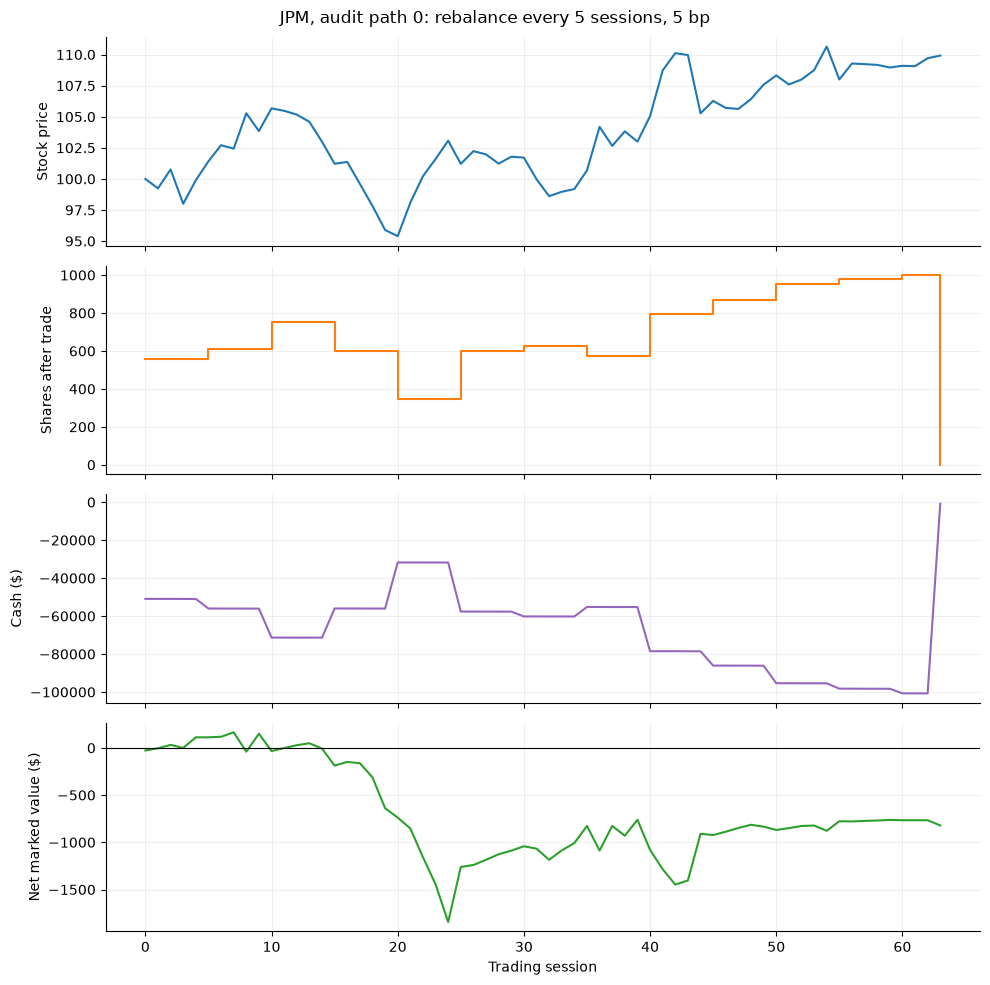

In [8]:
fig, axes = plt.subplots(4, 1, figsize=(10, 10), sharex=True)
axes[0].plot(ledger["step"], ledger["spot"], color="tab:blue")
axes[0].set_ylabel("Stock price")
axes[1].step(ledger["step"], ledger["shares_after"], where="post", color="tab:orange")
axes[1].set_ylabel("Shares after trade")
axes[2].plot(ledger["step"], ledger["cash"], color="tab:purple")
axes[2].set_ylabel("Cash ($)")
axes[3].plot(ledger["step"], ledger["net_value"], color="tab:green")
axes[3].axhline(0, color="black", linewidth=0.8)
axes[3].set(ylabel="Net marked value ($)", xlabel="Trading session")
fig.suptitle(f"{OPTION_NAME}, audit path {AUDIT_PATH}: {policy_label.lower()}, {COST_BPS:g} bp")
fig.tight_layout()
plt.show()

## 7 · Explain final settlement

On the last session, accrue interest on the previous cash balance, liquidate the stock, charge the liquidation cost, and pay `units * max(S_T - K, 0)`. The remaining cash is the terminal net P&L, since no stock or option liability remains.

The following waterfall lists signed cash contributions. The call payoff is a negative cash flow for the short position. The cost has already been charged through cash; it must not be subtracted again from terminal P&L.

In [9]:
last = ledger.iloc[-1]
settlement_cashflows = pd.Series({
    "cash_before_final_session": ledger.iloc[-2]["cash"],
    "final_session_interest": last["interest"],
    "stock_liquidation_proceeds": last["stock_cashflow"],
    "liquidation_cost": -last["transaction_cost"],
    "call_payoff_paid": -last["payoff_paid"],
}, name="cash_contribution")
settlement_table = settlement_cashflows.to_frame()
settlement_table["running_cash"] = settlement_cashflows.cumsum()
display(settlement_table.round(4))
np.testing.assert_allclose(
    last["payoff_paid"], single.units[0] * max(last["spot"] - single.strikes[0], 0), atol=1e-9, rtol=0
)
np.testing.assert_allclose(settlement_cashflows.sum(), last["cash"], atol=1e-8, rtol=0)
print(f"Terminal stock price: {last['spot']:.4f}")
print(f"Final net P&L for audit path {AUDIT_PATH}: ${last['cash']:,.4f}")

,cash_contribution,running_cash
cash_before_final_session,-100736.4245,-100736.4245
final_session_interest,-15.9912,-100752.4156
stock_liquidation_proceeds,109904.8402,9152.4246
liquidation_cost,-54.9524,9097.4722
call_payoff_paid,-9918.8393,-821.3671


Terminal stock price: 109.9188
Final net P&L for audit path 0: $-821.3671


## 8 · Isolate the effect of transaction costs

Run the **same hedge policy on exactly the same paths**, changing only the stock trading cost to zero. Trades are identical because the delta rule does not depend on cash or transaction costs in this model.

For every outcome:

$$\text{zero-cost P\&L} - \text{costly P\&L} = \text{costs accumulated to expiry at the financing rate}.$$

Nominal costs sum fees when charged. Financed costs also include the terminal effect of paying those fees earlier. With a positive rate, financed costs are at least nominal costs. Their difference is already reflected in cash and net P&L.

In [10]:
gross = hedge(single, single_paths, hedge_every=HEDGE_EVERY, cost_bps=0.0)
cost_identity_residual = gross.terminal_pnl - result.terminal_pnl - result.financed_costs
np.testing.assert_allclose(cost_identity_residual, 0.0, atol=1e-8, rtol=0)
np.testing.assert_allclose(gross.turnover, result.turnover, atol=1e-9, rtol=0)
np.testing.assert_array_equal(gross.trade_counts, result.trade_counts)

cost_check = pd.DataFrame({
    "mean_nominal_cost": [result.nominal_costs[:, 0].mean()],
    "mean_financed_cost": [result.financed_costs[:, 0].mean()],
    "mean_PnL_reduction": [(gross.terminal_pnl[:, 0] - result.terminal_pnl[:, 0]).mean()],
    "max_cost_identity_residual": [np.abs(cost_identity_residual).max()],
}, index=pd.Index([OPTION_NAME], name="name"))
display(cost_check.round(6))
print("Path-by-path financed-cost identity and identical-trade checks passed.")

,mean_nominal_cost,mean_financed_cost,mean_PnL_reduction,max_cost_identity_residual
name,,,,
JPM,111.845709,112.392094,112.392094,0.0


Path-by-path financed-cost identity and identical-trade checks passed.


## 9 · Inspect the distribution across all paths

Each outcome is an individual trading result. `summarize(...)` reports dollar metrics for the terminal P&L distribution:

- `mean_pnl`: average simulated net P&L; `mean_se`: Monte Carlo uncertainty in that average.
- `pnl_std`: variability of trading outcomes within this model.
- `rmse`: root mean squared P&L relative to zero.
- `pnl_p05`: the fifth percentile of P&L.
- `loss_es95`: minus the mean of the worst 5% of outcomes, rounded up to a whole observation count. It can be negative if even that tail is profitable.
- Cost, turnover and trade-count columns describe implementation activity. Turnover includes entry and liquidation.

Mean SE is not economic risk and is not an uncertainty interval for tail losses. The zero-cost and costly outcomes are paired because the same paths are used. This notebook illustrates one policy; frequency comparisons belong in notebook 02.

,,paths,mean_pnl,mean_se,pnl_std,rmse,pnl_p05,loss_es95
case,name,,,,,,,
zero_cost,JPM,5000,-19.9814,14.3397,1013.9687,1014.0641,-1716.8420,2404.7918
with_cost,JPM,5000,-132.3735,14.4410,1021.1314,1029.5745,-1849.5845,2547.8420


,,mean_cost,mean_financed_cost,mean_turnover,mean_trades
case,name,,,,
zero_cost,JPM,0.0000,0.0000,223691.4186,13.9684
with_cost,JPM,111.8457,112.3921,223691.4186,13.9684


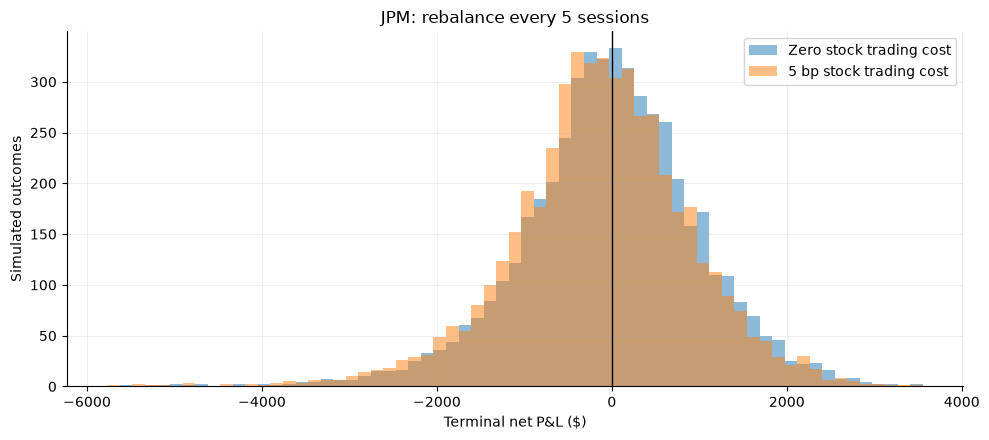

In [11]:
summary = summarize(result)
zero_cost_summary = summarize(gross)
comparison = pd.concat({
    "zero_cost": zero_cost_summary.loc[[OPTION_NAME]],
    "with_cost": summary.loc[[OPTION_NAME]],
}, names=["case", "name"])
display(comparison[[
    "paths", "mean_pnl", "mean_se", "pnl_std", "rmse", "pnl_p05", "loss_es95"
]].round(4))
display(comparison[["mean_cost", "mean_financed_cost", "mean_turnover", "mean_trades"]].round(4))

zero_cost_pnl = gross.terminal_pnl[:, 0]
net_pnl = result.terminal_pnl[:, 0]
bins = np.histogram_bin_edges(np.concatenate([zero_cost_pnl, net_pnl]), bins=65)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(zero_cost_pnl, bins=bins, alpha=0.5, label="Zero stock trading cost")
ax.hist(net_pnl, bins=bins, alpha=0.5, label=f"{COST_BPS:g} bp stock trading cost")
ax.axvline(0, color="black", linewidth=1)
ax.set(xlabel="Terminal net P&L ($)", ylabel="Simulated outcomes", title=f"{OPTION_NAME}: {policy_label.lower()}")
ax.legend()
fig.tight_layout()
plt.show()

## 10 · Record the actual experiment

The record includes the **joint study used for path generation**, the selected single-name trading book, the seed, path count, audit path, hedge interval, cost assumption and hedge volatility. Source hashes include the consolidated Black–Scholes module and accounting harness.

The notebook code hash excludes execution counts and rendered outputs. The record is displayed here; no additional export is performed. The run record identifies the exact shared study-file hash and the explicitly chosen policy parameters.

In [12]:
run_record = provenance(study_book, study_scenario, SEED, N_PATHS)
run_record["option_kind"] = "European call"
run_record["position_side"] = "short"
run_record["traded_book"] = asdict(single)
run_record["policy"] = {
    "selected_name": OPTION_NAME,
    "hedge_every": HEDGE_EVERY,
    "cost_bps": COST_BPS,
    "audit_path": AUDIT_PATH,
    "hedge_vols": list(single.pricing_vols),
}
run_record["path_generation"] = "Generate joint study paths, then select the named stock; same dimensions and seed as setup."
run_record["input_source"] = "Shared validated config/illustrative_study.json; notebook controls remain explicit."
run_record["python_executable"] = sys.executable
notebook_path = ROOT / "Hedging_Study_Notebooks" / "01_single_option_ledger.ipynb"
notebook_source = json.loads(notebook_path.read_text())
code_text = "\n\n".join(
    "".join(cell["source"]) for cell in notebook_source["cells"] if cell["cell_type"] == "code"
)
run_record["notebook_code_sha256"] = sha256(code_text.encode()).hexdigest()
run_record["shared_input_source"] = shared_config["shared_input_source"]
print(json.dumps(run_record, indent=2))

{
  "book": {
    "names": [
      "JPM",
      "PNC",
      "GS"
    ],
    "spots": [
      100.0,
      100.0,
      100.0
    ],
    "strikes": [
      100.0,
      100.0,
      100.0
    ],
    "notionals": [
      100000.0,
      100000.0,
      100000.0
    ],
    "pricing_vols": [
      0.22,
      0.28,
      0.26
    ],
    "steps": 63,
    "sessions_per_year": 252,
    "rate": 0.04
  },
  "scenario": {
    "path_vols": [
      0.22,
      0.28,
      0.26
    ],
    "correlation": [
      [
        1.0,
        0.65,
        0.7
      ],
      [
        0.65,
        1.0,
        0.55
      ],
      [
        0.7,
        0.55,
        1.0
      ]
    ]
  },
  "seed": 20261105,
  "n_paths": 5000,
  "measure": "Q; drift equals constant financing rate; no dividends",
  "versions": {
    "python": "3.14.8",
    "numpy": "2.5.4",
    "scipy": "1.18.1",
    "pandas": "3.1.1"
  },
  "source_sha256": {
    "BlackScholes_Functions/BlackScholes_D1D2_Price_Payoff_Greeks.py": "06dd465b

## What this notebook establishes

The accounting reconciles from opening premium through borrowing/lending, stock rebalances, costs, liquidation and call settlement. The final account has no shares or option liability, so its cash equals terminal net P&L. The matched zero-cost comparison isolates the financed effect of stock trading costs without subtracting costs twice.

Initial delta neutrality does not eliminate gamma, discrete-hedging error or transaction costs. The displayed P&L distribution remains conditional on illustrative Q-model assumptions. Dividends, option spreads, margin and exercise/assignment are outside the current model.

Next: **02_three_name_portfolio.ipynb** applies the accounting across names and compares hedge frequencies. That notebook loads the same shared model assumptions and declares its own policy controls.